# <span style="color:darkblue"> The Birthday Problem </span>

<font size="5">

Here is a question we can answer by simulation: if 50 people are in a room, how likely is it that *at least two* of them share a birthday?

Instead of working out the probability with a formula, we will *imagine many random rooms of 50 people*, check each room for a shared birthday, and see how often it happens. To keep the numbers simple, we will assume every month has 30 days (so there are 12 × 30 = 360 possible birthdays).

We will build up to the full simulation one piece at a time.

<font size = "5">

### Loop Warm-Up

Before getting started, let's review two ways to use `for` loops.

1. Use a `for` loop to print each day in the `days` list.
2. Use `range()` and `len()` to print each day by accessing it with its index.

In [2]:
days = [3, 8, 14, 21, 27]

for day in days:
    print(day)



N = len(days)

for i in range(N):
    print(days[i])

3
8
14
21
27
3
8
14
21
27


In [3]:
import random
# The 50 people in our room (each entry is [name, month, day, year])
birthdays = [
    ["Abed", "March", 23, 2007],
    ["Britta", "July", 14, 1998],
    ["Jeff", "December", 8, 1990],
    ["Shirley", "January", 19, 1990],
    ["Annie", "September", 27, 2007],
    ["Troy", "June", 5, 2007],
    ["Pierce", "December", 30, 1962],
    ["Chang", "April", 17, 1987],
    ["Craig", "August", 11, 1985],
    ["Magnitude", "February", 22, 1983],
    ["Garrett", "October", 3, 2001],
    ["Vicki", "May", 29, 2003],
    ["Todd", "March", 16, 1997],
    ["Starburns", "July", 7, 1982],
    ["Neil", "January", 25, 1998],
    ["Leonard", "November", 13, 1993],
    ["Willy", "September", 4, 1981],
    ["Pavel", "June", 21, 1980],
    ["Quendra", "December", 9, 1982],
    ["Rich", "April", 28, 1986],
    ["Duncan", "August", 15, 1987],
    ["Hickey", "February", 6, 1996],
    ["Buzz", "October", 24, 1999],
    ["Rachel", "May", 18, 1980],
    ["Ian", "March", 12, 1997],
    ["Elroy", "July", 30, 1986],
    ["Frankie", "November", 2, 2002],
    ["Natalie", "September", 20, 2000],
    ["Owen", "June", 11, 2002],
    ["Paula", "December", 26, 1997],
    ["Quinn", "April", 1, 1993],
    ["Roger", "August", 17, 1987],
    ["Sara", "February", 8, 1994],
    ["Tim", "October", 22, 1998],
    ["Uma", "May", 14, 1988],
    ["Victor", "January", 29, 2005],
    ["Wendy", "July", 5, 2007],
    ["Xavier", "March", 19, 1980],
    ["Yolanda", "November", 10, 2004],
    ["Zara", "September", 3, 2005],
    ["Alex", "June", 27, 1985],
    ["Blake", "December", 16, 2002],
    ["Casey", "April", 7, 1993],
    ["Dana", "August", 23, 1990],
    ["Eli", "February", 18, 1988],
    ["Fiona", "October", 12, 1984],
    ["George", "May", 25, 1986],
    ["Hana", "January", 6, 2004],
    ["Ivan", "July", 21, 1990],
    ["Julia", "March", 15, 1983],
]

months = ["January", "February", "March", "April",
          "May", "June", "July", "August",
          "September", "October", "November", "December"]

print(len(birthdays), "people in the room")

50 people in the room


<font size = "5">

**1.** Take the first person out of `birthdays` and give them a brand-new random birthday, while keeping their name and year.

- Make a **copy** of the person first (remember from Lecture 6: without `.copy()`, you would change the original `birthdays` list!).
- Print the person before and after.

In [4]:
import numpy as np

temp = birthdays[0].copy()
print(temp)

temp = ["Abed", random.choice(months), np.random.randint(1, 30), np.random.randint(1980, 2008)]
print(temp)

['Abed', 'March', 23, 2007]
['Abed', 'September', 4, 1991]


<font size = "5">

**2.** Now do that for every person in the room. Starting from an empty list, use a `for` loop to build a new list called `room`, where each entry is a copy of a real person but with a random month and day.

Print the first few entries and check that `len(room)` is 50.

*(We keep the `[name, month, day, year]` format so that later we can say exactly **who** shares a birthday.)*

In [5]:
room = []
new_birthdays = birthdays.copy()

for person in new_birthdays:
    name = person[0]
    year = np.random.randint(1980, 2008)
    new_month = random.choice(months)
    new_day = np.random.randint(1, 30)
    room.append([name, new_month, new_day, year])

print(room[0:4])
print(len(room))

[['Abed', 'September', 23, 1994], ['Britta', 'November', 11, 2007], ['Jeff', 'October', 11, 1988], ['Shirley', 'July', 5, 2004]]
50


<font size = "5">

**3.** Using an `if` / `else` statement with `and`, check whether the first two people in `room` share a birthday, and print "match" if they do and "miss" if they don't.


In [6]:
if room[0][1] == room[1][1] and room[0][2] == room[1][2]:
      print("match")
else:
      print("miss")

miss


<font size = "5">

**4.** Now check the first person against *everyone else* in the room.

- Create `found = False` before the loop.
- Loop over positions 1, 2, 3, ... and compare person 0 to the person at each position (month and day).
- If you find a match, print who it is, set `found = True`, and `break`.
- Print `found` at the end.

In [7]:
found = False

for i in range(1, len(room)):
     if room[0][1] == room[i][1] and room[0][2] == room[i][2]:
        print(room[i][0])
        found = True
        break

print(found)

Blake
True


<font size = "5">

**5.** To answer the real question we must check *every pair* of people, using a loop inside a loop:

- The **outer** loop picks the first person of the pair, `room[i]`.
- The **inner** loop picks a *later* person, `room[j]`, so we never compare a person to themselves or check the same pair twice. We get "later" people with `range(i + 1, num_people)`, which produces i+1, i+2, ... , num_people - 1.

Use a `found = False` flag, and print the names whenever you find a matching pair.

In [8]:
found = False

for i in range(len(room)):
     for j in range(i + 1, len(room)):
        if room[i][1] == room[j][1] and room[i][2] == room[j][2]:
            print(room[i][0], room[j][0])
            found = True

print(found)

Abed Blake
Quendra Casey
Rich Ian
Natalie Alex
True


<font size = "5">

**6.** Putting Exercises 2 and 5 together, one **trial** is: *fill the room with random birthdays, then check whether any two match.* Combine them into a single cell that produces one `True`/`False` answer for one random room.


In [9]:
room = []
found = False

for person in new_birthdays:
    name = person[0]
    year = np.random.randint(1980, 2008)
    new_month = random.choice(months)
    new_day = np.random.randint(1, 31)
    room.append([name, new_month, new_day, year])

for i in range(len(room)):
    for j in range(i + 1, len(room)):
        if room[i][1] == room[j][1] and room[i][2] == room[j][2]:
            found = True

print(found)

True


<font size = "5">

**7.** A single trial only says `True` or `False`. To *estimate* a probability, repeat the trial many times and count how often a shared birthday happens.

Wrap the whole trial from Exercise 6 inside an **outer loop** that runs 100 times. Keep a counter `num_found` that goes up by 1 whenever a trial has a shared birthday, then divide by the number of trials.

Out of 100 random rooms of 50 people, how many had at least two people sharing a birthday? Are you surprised?

In [10]:
num_trials = 100
num_found = 0

for trial in range(num_trials):
    room = []
    found = False

    for person in birthdays:
        new_person = person.copy()
        new_person[1] = random.choice(months)
        new_person[2] = np.random.randint(1, 31)
        room.append(new_person)

    for i in range(len(room)):
        for j in range(i + 1, len(room)):
            if room[i][1] == room[j][1] and room[i][2] == room[j][2]:
                found = True

    if found:
        num_found = num_found + 1

print("In", num_found, "out of", num_trials, "rooms, at least two people shared a birthday.")
print("Estimated probability:", num_found / num_trials)

In 99 out of 100 rooms, at least two people shared a birthday.
Estimated probability: 0.99


<font size = "5">

**8.** The surprising part of the birthday problem is how *few* people you need. Estimate the probability for several room sizes and draw a bar plot.

- For each room size in `size = [5, 10, 25, 50]`, run 100 trials. 
  - append the estimated probability of a match for that room size to a list called `estimates`.
- Collect the estimates into a list and plot them with `plt.bar`.

Watch what happens around 25 people.

Room sizes: [5, 10, 25, 50]
Estimates: [0.03, 0.12, 0.54, 0.97]


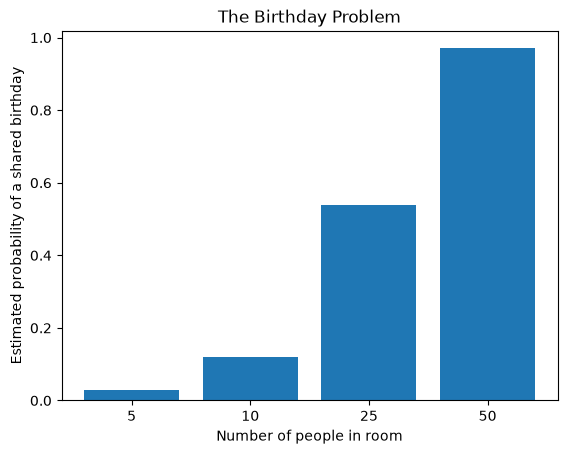

In [11]:
import matplotlib.pyplot as plt

size = [5, 10, 25, 50]
num_trials = 100
estimates = []

for n in size:
    num_found = 0

    for trial in range(num_trials):
        room = []
        found = False

        for person in birthdays[0:n]:
            new_person = person.copy()
            new_person[1] = random.choice(months)
            new_person[2] = np.random.randint(1, 31)
            room.append(new_person)

        for i in range(len(room)):
            for j in range(i + 1, len(room)):
                if room[i][1] == room[j][1] and room[i][2] == room[j][2]:
                    found = True

        if found:
            num_found = num_found + 1

    estimates.append(num_found / num_trials)

print("Room sizes:", size)
print("Estimates:", estimates)

plt.bar([str(n) for n in size], estimates)
plt.xlabel("Number of people in room")
plt.ylabel("Estimated probability of a shared birthday")
plt.title("The Birthday Problem")
plt.show()